# Model V

### Audio spectrogram Transformer - wyniki treningu

Biblioteki

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

In [3]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score
)

from model import InstrumentAST
from trening import get_device
from przygotowanie_danych import (INSTRUMENTS, create_datasets, create_loaders)

### Wybór modelu

In [4]:
learning_id = 1
results_dir = Path("wyniki")

### Wczytywanie informacji o eksperymentach

In [5]:
experiments = pd.read_csv(results_dir / "modele.csv")

experiment = experiments.loc[experiments["Learning_ID"] == learning_id].iloc[0]

### Odczyt parametrów eksperymentu

In [6]:
dataset = experiment["Dataset"]
model_name = experiment["Model"]

batch_size = int(experiment["Batch size"])
learning_rate = float(experiment["Learning rate"])

dropout = float(experiment["Dropout"])
hidden_size = int(experiment["Hidden size"])
num_hidden_layers = int(experiment["Transformer layers"])
num_attention_heads = int(experiment["Attention heads"])

best_epoch = int(experiment["Best epoch"])
best_val_loss = float(experiment["Best val loss"])
training_time = float(experiment["Training time [min]"])

print("Parametry eksperymentu:")
print(f"Learning ID: {learning_id}")
print(f"Dataset: {dataset}")
print(f"Model: {model_name}")
print(f"Batch size: {batch_size}")
print(f"Learning rate: {learning_rate}")
print(f"Dropout: {dropout}")
print(f"Hidden size: {hidden_size}")
print(f"Transformer layers: {num_hidden_layers}")
print(f"Attention heads: {num_attention_heads}")
print(f"Best epoch: {best_epoch}")
print(f"Best val loss: {best_val_loss:.4f}")
print(f"Training time: {training_time:.4f} min")

Parametry eksperymentu:
Learning ID: 1
Dataset: 1_1
Model: AST
Batch size: 8
Learning rate: 0.0001
Dropout: 0.1
Hidden size: 384
Transformer layers: 6
Attention heads: 6
Best epoch: 16
Best val loss: 0.2692
Training time: 68.1286 min


### Przygotowanie danych

In [9]:
train_dataset, val_dataset, test_dataset = create_datasets(dataset)

train_loader, val_loader, test_loader = create_loaders(
    train_dataset,
    val_dataset,
    test_dataset,
    batch_size=batch_size
)

sample_X, _ = train_dataset[0]

num_mel_bins = sample_X.shape[-2]
max_length = sample_X.shape[-1]

Wczytuję spektrogramy z: /Users/khaczkiewicz/Documents/projekt-instrumenty/instrument-recognition-project/spectrograms/1_1


### Odtworzenie modelu i wczytanie wag

In [10]:
device = get_device()
print(f"Urządzenie: {device}")

model = InstrumentAST(
    num_mel_bins=num_mel_bins,
    max_length=max_length,
    dropout=dropout
).to(device)

weights_file = results_dir / f"{learning_id}.pth"

model.load_state_dict(
    torch.load(weights_file, map_location=device, weights_only=True)
)

model.eval()

Urządzenie: mps


InstrumentAST(
  (model): ASTForAudioClassification(
    (audio_spectrogram_transformer): ASTModel(
      (embeddings): ASTEmbeddings(
        (patch_embeddings): ASTPatchEmbeddings(
          (projection): Conv2d(1, 384, kernel_size=(16, 16), stride=(10, 10))
        )
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (layers): ModuleList(
        (0-5): 6 x ASTLayer(
          (attention): ASTAttention(
            (q_proj): Linear(in_features=384, out_features=384, bias=True)
            (k_proj): Linear(in_features=384, out_features=384, bias=True)
            (v_proj): Linear(in_features=384, out_features=384, bias=True)
            (o_proj): Linear(in_features=384, out_features=384, bias=True)
          )
          (layernorm_before): LayerNorm((384,), eps=1e-12, elementwise_affine=True, bias=True)
          (layernorm_after): LayerNorm((384,), eps=1e-12, elementwise_affine=True, bias=True)
          (mlp): ASTMLP(
            (activation_fn): GELUActivation()
      

### Wczytanie historii treningu

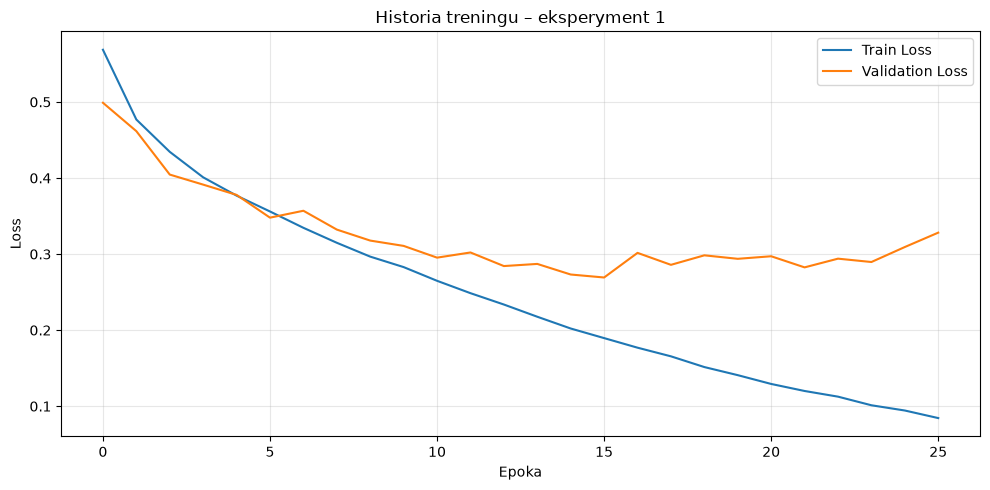

In [11]:
history = pd.read_csv(
    results_dir / f"history_{learning_id}.csv",
    index_col="epoch"
)

plt.figure(figsize=(10, 5))

plt.plot(
    history.index,
    history["train_loss"],
    label="Train Loss"
)

plt.plot(
    history.index,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoka")
plt.ylabel("Loss")
plt.title(f"Historia treningu – eksperyment {learning_id}")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Wyznaczenie optymalnych progów decyzyjnych

In [12]:
# Pobranie prawdopodobieństw i etykiet ze zbioru walidacyjnego
all_probabilities = []
all_labels = []

model.eval()

with torch.no_grad():
    for X, y in val_loader:
        X = X.to(device)

        logits = model(X)
        probabilities = torch.sigmoid(logits)

        all_probabilities.append(probabilities.cpu().numpy())
        all_labels.append(y.numpy())

all_probabilities = np.concatenate(all_probabilities, axis=0)
all_labels = np.concatenate(all_labels, axis=0)


# Obliczanie Micro-F1 i Macro-F1 dla wybranego progu
def calculate_f1(threshold):
    predictions = (all_probabilities >= threshold).astype(int)

    micro = f1_score(
        all_labels,
        predictions,
        average="micro",
        zero_division=0
    )

    macro = f1_score(
        all_labels,
        predictions,
        average="macro",
        zero_division=0
    )

    return micro, macro


# Wstępne sprawdzenie progów
thresholds_coarse = np.linspace(0.1, 0.9, 17)

results_coarse = [
    calculate_f1(t) for t in thresholds_coarse
]

micro_coarse = np.array([r[0] for r in results_coarse])
macro_coarse = np.array([r[1] for r in results_coarse])


# Wybór najlepszego progu z siatki wstępnej
estimated_micro = thresholds_coarse[np.argmax(micro_coarse)]
estimated_macro = thresholds_coarse[np.argmax(macro_coarse)]


# Dokładniejsze sprawdzenie w otoczeniu najlepszego progu
thresholds_micro = np.linspace(
    max(0.001, estimated_micro - 0.05),
    min(0.999, estimated_micro + 0.05),
    101
)

thresholds_macro = np.linspace(
    max(0.001, estimated_macro - 0.05),
    min(0.999, estimated_macro + 0.05),
    101
)

micro_fine = np.array([
    calculate_f1(t)[0] for t in thresholds_micro
])

macro_fine = np.array([
    calculate_f1(t)[1] for t in thresholds_macro
])


# Wyznaczenie najlepszych progów
best_micro_idx = np.argmax(micro_fine)
best_macro_idx = np.argmax(macro_fine)

best_micro_threshold = thresholds_micro[best_micro_idx]
best_macro_threshold = thresholds_macro[best_macro_idx]

best_micro_f1 = micro_fine[best_micro_idx]
best_macro_f1 = macro_fine[best_macro_idx]

print(
    f"Best Micro-F1: {best_micro_f1:.4f} "
    f"| Threshold: {best_micro_threshold:.4f}"
)

print(
    f"Best Macro-F1: {best_macro_f1:.4f} "
    f"| Threshold: {best_macro_threshold:.4f}"
)

/opt/anaconda3/envs/cnn/lib/python3.14/site-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Best Micro-F1: 0.8862 | Threshold: 0.3920
Best Macro-F1: 0.8836 | Threshold: 0.3920


### Ocena modelu na zbiorze testowym

In [13]:
# Predykcje modelu na zbiorze testowym
test_probabilities = []
test_labels = []

model.eval()

with torch.no_grad():
    for X, y in test_loader:
        X = X.to(device)

        logits = model(X)
        probabilities = torch.sigmoid(logits)

        test_probabilities.append(probabilities.cpu().numpy())
        test_labels.append(y.numpy())

test_probabilities = np.concatenate(test_probabilities, axis=0)
test_labels = np.concatenate(test_labels, axis=0)


# Obliczanie metryk dla wybranego progu
def calculate_metrics(probabilities, labels, threshold):
    predictions = (probabilities >= threshold).astype(int)

    micro = f1_score(
        labels,
        predictions,
        average="micro",
        zero_division=0
    )

    macro = f1_score(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    return predictions, micro, macro


# Ocena dla progu optymalizującego Macro-F1
predictions_macro, test_micro_macro, test_macro_macro = calculate_metrics(
    test_probabilities,
    test_labels,
    best_macro_threshold
)

# Ocena dla progu optymalizującego Micro-F1
predictions_micro, test_micro_micro, test_macro_micro = calculate_metrics(
    test_probabilities,
    test_labels,
    best_micro_threshold
)

print("Wyniki na zbiorze testowym:")
print(
    f"Próg Macro-F1 ({best_macro_threshold:.4f}): "
    f"Micro-F1 = {test_micro_macro:.4f}, "
    f"Macro-F1 = {test_macro_macro:.4f}"
)

print(
    f"Próg Micro-F1 ({best_micro_threshold:.4f}): "
    f"Micro-F1 = {test_micro_micro:.4f}, "
    f"Macro-F1 = {test_macro_micro:.4f}"
)

/opt/anaconda3/envs/cnn/lib/python3.14/site-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Wyniki na zbiorze testowym:
Próg Macro-F1 (0.3920): Micro-F1 = 0.8885, Macro-F1 = 0.8856
Próg Micro-F1 (0.3920): Micro-F1 = 0.8885, Macro-F1 = 0.8856


### Metryki dla poszczególnych instrumentów

In [14]:
instrument_names = list(INSTRUMENTS.values())


def calculate_instrument_metrics(labels, predictions):
    precision = precision_score(
        labels,
        predictions,
        average=None,
        zero_division=0
    )

    recall = recall_score(
        labels,
        predictions,
        average=None,
        zero_division=0
    )

    f1 = f1_score(
        labels,
        predictions,
        average=None,
        zero_division=0
    )

    return pd.DataFrame({
        "Instrument": instrument_names,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })


# Wyniki dla progu optymalizującego Macro-F1
metrics_macro_df = calculate_instrument_metrics(
    test_labels,
    predictions_macro
)

display(metrics_macro_df.round(4))


# Wyniki dla progu optymalizującego Micro-F1
metrics_micro_df = calculate_instrument_metrics(
    test_labels,
    predictions_micro
)

display(metrics_micro_df.round(4))


,Instrument,Precision,Recall,F1-score
0,Gitara akustyczna,0.8337,0.9048,0.8678
1,Saksofon altowy,0.8021,0.8567,0.8285
2,Fortepian,0.9132,0.8653,0.8886
3,Perkusja,0.9718,0.9869,0.9793
4,Gitara basowa,0.9347,0.9628,0.9486
5,Flet,0.8290,0.7955,0.8119
6,Sekcja smyczkowa,0.8587,0.8912,0.8746


,Instrument,Precision,Recall,F1-score
0,Gitara akustyczna,0.8337,0.9048,0.8678
1,Saksofon altowy,0.8021,0.8567,0.8285
2,Fortepian,0.9132,0.8653,0.8886
3,Perkusja,0.9718,0.9869,0.9793
4,Gitara basowa,0.9347,0.9628,0.9486
5,Flet,0.8290,0.7955,0.8119
6,Sekcja smyczkowa,0.8587,0.8912,0.8746


#### Porównanie *F1-score* dla różnych instrumentów

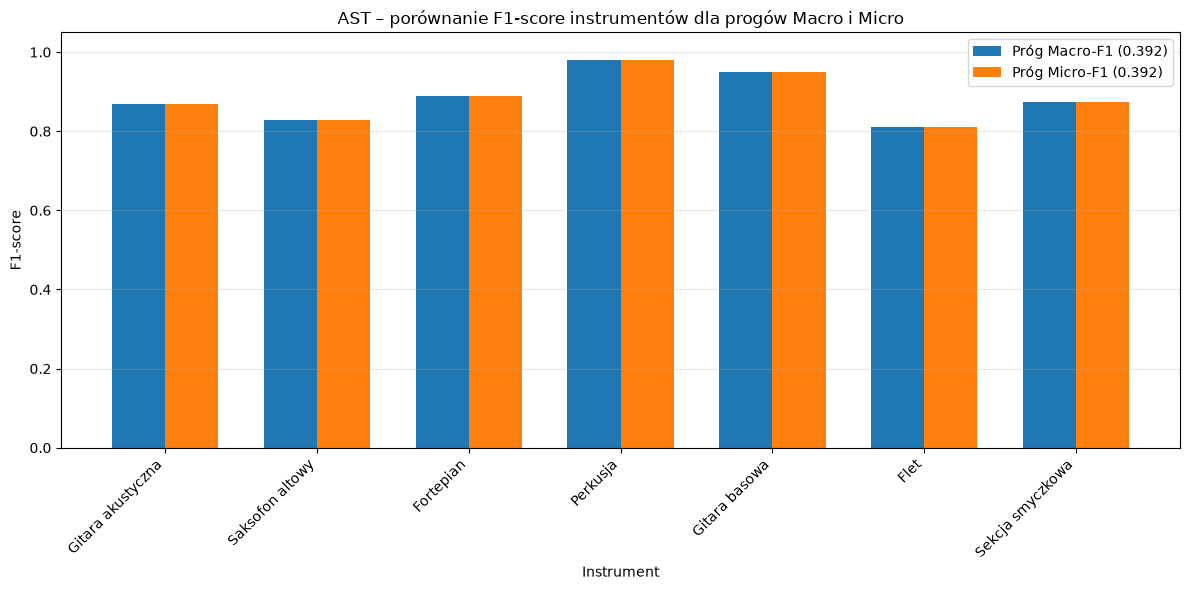

In [15]:
plt.figure(figsize=(12, 6))

x = np.arange(len(instrument_names))
width = 0.35

plt.bar(
    x - width / 2,
    metrics_macro_df["F1-score"],
    width,
    label=f"Próg Macro-F1 ({best_macro_threshold:.3f})"
)

plt.bar(
    x + width / 2,
    metrics_micro_df["F1-score"],
    width,
    label=f"Próg Micro-F1 ({best_micro_threshold:.3f})"
)

plt.xlabel("Instrument")
plt.ylabel("F1-score")
plt.title(
    f"{model_name} – porównanie F1-score instrumentów "
    "dla progów Macro i Micro"
)

plt.xticks(x, instrument_names, rotation=45, ha="right")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


### Zapis wyników

In [17]:
metrics_file = results_dir / "wyniki.csv"

processed_ids = (
    pd.read_csv(metrics_file)["Learning_ID"].tolist()
    if metrics_file.exists()
    else []
)

if learning_id not in processed_ids:

    f1_results = pd.DataFrame([{
        "Learning_ID": learning_id,
        "Dataset": dataset,
        "Model": model_name,
        "Batch size": batch_size,
        "Learning rate": learning_rate,
        "Dropout": dropout,
        "Hidden size": hidden_size,
        "Transformer layers": num_hidden_layers,
        "Attention heads": num_attention_heads,
        "Best epoch": best_epoch,
        "Best val loss": best_val_loss,
        "Training time [min]": training_time,

        "Best Micro F1 (validation)": best_micro_f1,
        "Best Micro threshold": best_micro_threshold,

        "Best Macro F1 (validation)": best_macro_f1,
        "Best Macro threshold": best_macro_threshold,

        "Test Micro F1 (Macro threshold)": test_micro_macro,
        "Test Macro F1 (Macro threshold)": test_macro_macro,

        "Test Micro F1 (Micro threshold)": test_micro_micro,
        "Test Macro F1 (Micro threshold)": test_macro_micro
    }])

    f1_results.to_csv(
        metrics_file,
        mode="a",
        header=not metrics_file.exists(),
        index=False
    )

    print("Wyniki zapisane w wyniki.csv.")

else:
    print("Ten Learning_ID został już przetworzony. Pomijam zapis.")

Wyniki zapisane w wyniki.csv.
